In [1]:
import pandas as pd
import xarray as xr
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.iolib.smpickle import load_pickle

import comp_utils

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
ncep_demand_his = xr.open_dataset('data/ncep_gfs_demand_20200920_20231027.nc')
ncep_demand_now = xr.open_dataset('data/ncep_gfs_demand_20231027_20240108.nc')

ncep_demand_his_df = ncep_demand_his.to_dataframe()
ncep_demand_now_df = ncep_demand_now.to_dataframe()

ncep_demand_now_df.index.rename(['ref_datetime','valid_datetime','point'],inplace=True)

combined_ncep_df =pd.concat([ncep_demand_his_df,ncep_demand_now_df])

combined_ncep_df.to_pickle('data/combined_ncep_demand_dataframe.pkl')

dwd_demand_his = xr.open_dataset('data/dwd_icon_eu_demand_20200920_20231027.nc')
dwd_demand_now = xr.open_dataset('data/dwd_icon_eu_demand_20231027_20240108.nc')

dwd_demand_his_df = dwd_demand_his.to_dataframe()
dwd_demand_now_df = dwd_demand_now.to_dataframe()

dwd_demand_now_df.index.rename(['valid_datetime','ref_datetime','point'],inplace=True)

combined_dwd_df =pd.concat([dwd_demand_his_df,dwd_demand_now_df])


In [3]:
dwd_demand_his_df.tail(20)

RelativeHumidity  Temperature  \
ref_datetime valid_datetime point                                  
2023-10-27   114            1             86.220345    11.472961   
                            2             87.985970     9.527649   
                            3             90.376595     8.373352   
                            4             93.735970     9.141907   
                            5             94.036751     8.795227   
                            6             96.659798     8.283508   
             117            0             91.136971    10.199615   
                            1             91.730721    12.172272   
                            2             90.115486     9.495514   
                            3             93.857674     7.927155   
                            4             94.453377     9.123444   
                            5             94.933846     7.510162   
                            6             97.886971     5.889069   
             120            0             92.279251    11.711029   
                            1             90.906204    13.375092   
                            2             96.876907    10.087006   
                            3             94.943314     9.512787   
                            4             96.318314     8.802826   
                            5             94.935501     7.152435   
                            6             96.480423     5.825287   

                                   TotalPrecipitation  WindDirection  \
ref_datetime valid_datetime point                                      
2023-10-27   114            1                0.263021     172.699036   
                            2                0.164062     210.646820   
                            3                0.010417     166.102234   
                            4                0.023438      59.494202   
                            5                0.000000     230.784927   
                            6                0.000000     240.824860   
             117            0                0.065104     181.329269   
                            1                0.091146     171.050598   
                            2                0.510417     176.502823   
                            3                1.312500     147.703003   
                            4                0.033854      73.319916   
                            5                0.000000     224.360245   
                            6                0.000000     209.312241   
             120            0                     NaN     173.579330   
                            1                     NaN     184.289093   
                            2                     NaN     167.642624   
                            3                     NaN     146.496796   
                            4                     NaN      74.014954   
                            5                     NaN     176.489807   
                            6                     NaN     157.453552   

                                   WindSpeed  latitude  longitude  
ref_datetime valid_datetime point                                  
2023-10-27   114            1       1.740683    51.453     -2.600  
                            2       1.441596    52.449     -1.926  
                            3       0.973828    53.175     -2.986  
                            4       2.023809    55.860     -4.264  
                            5       2.079076    53.875     -0.442  
                            6       1.021691    54.297     -1.533  
             117            0       1.584439    51.479     -0.451  
                            1       3.906966    51.453     -2.600  
                            2       2.038982    52.449     -1.926  
                            3       2.740403    53.175     -2.986  
                            4       3.181080    55.860     -4.264  
                            5       1.879521    53.875     -0.442  
 

In [4]:
combined_dwd_df.tail(20)

RelativeHumidity  Temperature  \
                        point                                  
120 2024-01-07 12:00:00 1             81.643288     4.854584   
                        2             87.346413     4.440521   
                        3             85.369850     5.059662   
                        4            100.000710    -2.864166   
                        5             77.662819     6.389740   
                        6             79.571022     4.870209   
    2024-01-07 18:00:00 0             76.729187     5.497345   
                        1             87.449890     4.826447   
                        2             85.037781     3.178986   
                        3             92.324890     1.511017   
                        4             92.506531    -0.224335   
                        5             82.889343     4.316681   
                        6             88.156921     3.288361   
    2024-01-08 00:00:00 0             84.140808     2.651764   
                        1             88.699402     1.789459   
                        2             86.496277     1.231842   
                        3             86.299011     2.980865   
                        4             89.304871     2.794342   
                        5             96.449402    -0.081635   
                        6             85.648621    -0.970306   

                               TotalPrecipitation  WindDirection  WindSpeed  \
                        point                                                 
120 2024-01-07 12:00:00 1                     NaN      63.170685   3.105150   
                        2                     NaN      37.680969   1.797948   
                        3                     NaN     358.557251   0.915421   
                        4                     NaN      28.077637   0.143991   
                        5                     NaN     340.317352   3.130249   
                        6                     NaN     326.985382   2.582050   
    2024-01-07 18:00:00 0                     NaN      12.017395   1.825780   
                        1                     NaN      34.335938   1.671224   
                        2                     NaN      32.914856   0.909843   
                        3                     NaN     267.003265   1.118456   
                        4                     NaN     224.746277   1.035885   
                        5                     NaN     286.876801   1.480494   
                        6                     NaN     318.857086   0.430042   
    2024-01-08 00:00:00 0                     NaN     312.719604   1.784005   
                        1                     NaN     301.168243   0.247816   
                        2                     NaN     249.425217   1.719162   
                        3                     NaN     271.153564   2.247655   
                        4                     NaN     233.120163   2.544438   
                        5                     NaN     261.730347   2.978364   
                        6                     NaN     237.605545   0.817830   

                               latitude  longitude  
                        point                       
120 2024-01-07 12:00:00 1        51.453     -2.600  
                        2        52.449     -1.926  
                        3        53.175     -2.986  
                        4        55.860     -4.264  
                        5        53.875     -0.442  
                        6        54.297     -1.533  
    2024-01-07 18:00:00 0        51.479     -0.451  
                        1        51.453     -2.600  
                        2        52.449     -1.926  
                        3        53.175     -2.986  
                        4        55.860     -4.264  
                        5        53.875     -0.442  
                        6        54.297     -1.533  
    2024-01-08 00:00:00 0        51.479     -0.451  
                        1        51

In [5]:
wind_speed_dwd = combined_dwd_df["WindSpeed"]
wind_rad = combined_dwd_df["WindDirection"]*np.pi/180

combined_dwd_df["WindX"] = wind_speed_dwd*np.cos(wind_rad)
combined_dwd_df["WindY"] = wind_speed_dwd*np.sin(wind_rad)


In [10]:
combined_dwd_df.fillna(0,inplace=True)

(-14.426454343259373,
 18.04821893597557,
 -19.316040192657542,
 12.414938106023357)

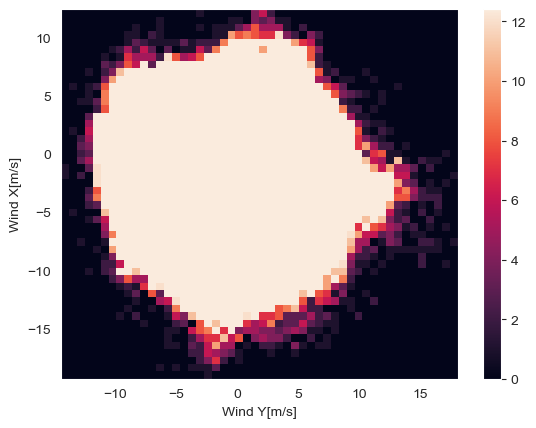

In [13]:
plt.hist2d(combined_dwd_df["WindX"],combined_dwd_df["WindY"],bins = (50,50),vmax = combined_dwd_df["WindY"].max())
plt.colorbar()
plt.ylabel("Wind X[m/s]")
plt.xlabel("Wind Y[m/s]")

ax = plt.gca()
ax.axis("tight")

In [14]:
from processors import *
ncep_files = ["data/ncep_gfs_demand_20200920_20231027.nc", "data/ncep_gfs_demand_20231027_20240108.nc"]
dwd_files = ["data/dwd_icon_eu_demand_20200920_20231027.nc", "data/dwd_icon_eu_demand_20231027_20240108.nc"]

ncep_df = process_dataset(ncep_files, '_ncep', 'solar')
dwd_df = process_dataset(dwd_files, '_dwd', 'solar')

In [17]:
dwd_df.head(20)

RelativeHumidity_dwd  \
datetime                  point latitude longitude                         
2020-09-21 00:00:00+00:00 0     51.479   -0.451                91.678833   
                          1     51.453   -2.600                86.387817   
                          2     52.449   -1.926                92.786255   
                          3     53.175   -2.986                93.172974   
                          4     55.860   -4.264                91.700317   
                          5     53.875   -0.442                95.034302   
                          6     54.297   -1.533                96.221802   
2020-09-21 01:00:00+00:00 0     51.479   -0.451                92.969925   
                          1     51.453   -2.600                88.850784   
                          2     52.449   -1.926                94.596878   
                          3     53.175   -2.986                94.264847   
                          4     55.860   -4.264                92.309769   
                          5     53.875   -0.442                95.600784   
                          6     54.297   -1.533                94.889847   
2020-09-21 02:00:00+00:00 0     51.479   -0.451                93.714752   
                          1     51.453   -2.600                91.169830   
                          2     52.449   -1.926                96.302643   
                          3     53.175   -2.986                95.599518   
                          4     55.860   -4.264                93.230377   
                          5     53.875   -0.442                96.562408   

                                                    Temperature_dwd  \
datetime                  point latitude longitude                    
2020-09-21 00:00:00+00:00 0     51.479   -0.451           13.038177   
                          1     51.453   -2.600           13.186615   
                          2     52.449   -1.926           10.747162   
                          3     53.175   -2.986            9.725677   
                          4     55.860   -4.264           10.413177   
                          5     53.875   -0.442            9.629974   
                          6     54.297   -1.533           10.002045   
2020-09-21 01:00:00+00:00 0     51.479   -0.451           12.550659   
                          1     51.453   -2.600           12.673706   
                          2     52.449   -1.926           10.353394   
                          3     53.175   -2.986            9.525269   
                          4     55.860   -4.264            9.981323   
                          5     53.875   -0.442            9.591675   
                          6     54.297   -1.533           10.012573   
2020-09-21 02:00:00+00:00 0     51.479   -0.451           12.112305   
                          1     51.453   -2.600           12.058594   
                          2     52.449   -1.926           10.006836   
                          3     53.175   -2.986            9.064453   
                          4     55.860   -4.264            9.412109   
                          5     53.875   -0.442            9.352539   

                                                    TotalPrecipitation_dwd  \
datetime                  point latitude longitude                           
2020-09-21 00:00:00+00:00 0     51.479   -0.451                        0.0   
                          1     51.453   -2.600                        0.0   
                          2     52.449   -1.926                        0.0   
                          3     53.175   -2.986                        0.0   
                          4     55.860   -4.264                        0.0   
                          5     53.875   -0.442                        0.0   
                          6     54.297   -1.533                        0.0   
2020-09-21 01:00:00+00:00 0     51.479   -0.451                        0.0   
                          1     51.4

In [15]:
# Load the energy data as y variable
energy_data = pd.read_csv("data/Energy_Data_20200920_20231027.csv")
energy_data["datetime"] = pd.to_datetime(energy_data["dtm"])
energy_data["Wind_MWh_credit"] = 0.5*energy_data["Wind_MW"] - energy_data["boa_MWh"]
energy_data["Solar_MWh_credit"] = 0.5*energy_data["Solar_MW"]
energy_data_subset = energy_data[['datetime','Wind_MWh_credit', 'Solar_MWh_credit']]

In [19]:
energy_data.head(50)

,dtm,MIP,Solar_MW,Solar_capacity_mwp,Solar_installedcapacity_mwp,Wind_MW,SS_Price,boa_MWh,DA_Price,datetime,Wind_MWh_credit,Solar_MWh_credit
0,2020-09-20T00:00:00Z,20.06,0.000000,2108.489754,2206.064655,996.284,2.50000,0.0,32.17,2020-09-20 00:00:00+00:00,498.142,0.000000
1,2020-09-20T00:30:00Z,19.77,0.000000,2108.489754,2206.064655,957.576,15.00000,0.0,32.17,2020-09-20 00:30:00+00:00,478.788,0.000000
2,2020-09-20T01:00:00Z,28.68,0.000000,2108.489754,2206.064655,941.044,47.95000,0.0,32.00,2020-09-20 01:00:00+00:00,470.522,0.000000
3,2020-09-20T01:30:00Z,28.97,0.000000,2108.489754,2206.064655,964.366,29.13000,0.0,32.00,2020-09-20 01:30:00+00:00,482.183,0.000000
4,2020-09-20T02:00:00Z,28.19,0.000000,2108.489754,2206.064655,918.432,28.95000,0.0,31.99,2020-09-20 02:00:00+00:00,459.216,0.000000
5,2020-09-20T02:30:00Z,28.24,0.000000,2108.489754,2206.064655,939.194,29.09013,0.0,31.99,2020-09-20 02:30:00+00:00,469.597,0.000000
6,2020-09-20T03:00:00Z,28.50,0.000000,2108.489754,2206.064655,978.682,30.90000,0.0,32.54,2020-09-20 03:00:00+00:00,489.341,0.000000
7,2020-09-20T03:30:00Z,29.18,0.000000,2108.489754,2206.064655,989.786,34.40000,0.0,32.54,2020-09-20 03:30:00+00:00,494.893,0.000000
8,2020-09-20T04:00:00Z,24.00,0.000000,2108.489754,2206.064655,1002.902,29.00000,0.0,32.28,2020-09-20 04:00:00+00:00,501.451,0.000000
9,2020-09-20T04:30:00Z,33.68,0.000000,2108.489754,2206.064655,1001.324,28.90000,0.0,32.28,2020-09-20 04:30:00+00:00,500.662,0.000000


In [ ]:
BOA = energy_data["boa_MWh"]

$$MIP = SSP - 0.07*(ACTUAL-TRADE)$$, so $$TRADE=ACTUAL- (SSP-MIP)/0.07$$, here $$ACTUAL = Wind credit（MWH) + Solar credit(MWh)$$

In [20]:
energy_data["Total_generation_MWh"] = energy_data["Wind_MWh_credit"] + energy_data["Solar_MWh_credit"]
energy_data["TRADE"] = energy_data["Total_generation_MWh"] - (energy_data["SS_Price"]-energy_data["MIP"])/0.07
energy_data.head(50)

,dtm,MIP,Solar_MW,Solar_capacity_mwp,Solar_installedcapacity_mwp,Wind_MW,SS_Price,boa_MWh,DA_Price,datetime,Wind_MWh_credit,Solar_MWh_credit,Total_generation_MWh,TRADE
0,2020-09-20T00:00:00Z,20.06,0.000000,2108.489754,2206.064655,996.284,2.50000,0.0,32.17,2020-09-20 00:00:00+00:00,498.142,0.000000,498.142000,748.999143
1,2020-09-20T00:30:00Z,19.77,0.000000,2108.489754,2206.064655,957.576,15.00000,0.0,32.17,2020-09-20 00:30:00+00:00,478.788,0.000000,478.788000,546.930857
2,2020-09-20T01:00:00Z,28.68,0.000000,2108.489754,2206.064655,941.044,47.95000,0.0,32.00,2020-09-20 01:00:00+00:00,470.522,0.000000,470.522000,195.236286
3,2020-09-20T01:30:00Z,28.97,0.000000,2108.489754,2206.064655,964.366,29.13000,0.0,32.00,2020-09-20 01:30:00+00:00,482.183,0.000000,482.183000,479.897286
4,2020-09-20T02:00:00Z,28.19,0.000000,2108.489754,2206.064655,918.432,28.95000,0.0,31.99,2020-09-20 02:00:00+00:00,459.216,0.000000,459.216000,448.358857
5,2020-09-20T02:30:00Z,28.24,0.000000,2108.489754,2206.064655,939.194,29.09013,0.0,31.99,2020-09-20 02:30:00+00:00,469.597,0.000000,469.597000,457.452286
6,2020-09-20T03:00:00Z,28.50,0.000000,2108.489754,2206.064655,978.682,30.90000,0.0,32.54,2020-09-20 03:00:00+00:00,489.341,0.000000,489.341000,455.055286
7,2020-09-20T03:30:00Z,29.18,0.000000,2108.489754,2206.064655,989.786,34.40000,0.0,32.54,2020-09-20 03:30:00+00:00,494.893,0.000000,494.893000,420.321571
8,2020-09-20T04:00:00Z,24.00,0.000000,2108.489754,2206.064655,1002.902,29.00000,0.0,32.28,2020-09-20 04:00:00+00:00,501.451,0.000000,501.451000,430.022429
9,2020-09-20T04:30:00Z,33.68,0.000000,2108.489754,2206.064655,1001.324,28.90000,0.0,32.28,2020-09-20 04:30:00+00:00,500.662,0.000000,500.662000,568.947714


In [21]:
energy_data.tail()

,dtm,MIP,Solar_MW,Solar_capacity_mwp,Solar_installedcapacity_mwp,Wind_MW,SS_Price,boa_MWh,DA_Price,datetime,Wind_MWh_credit,Solar_MWh_credit,Total_generation_MWh,TRADE
54379,2023-10-27T21:30:00Z,NaN,0.0,2331.383994,2487.180474,275.444,129.0,0.0,82.47,2023-10-27 21:30:00+00:00,137.722,0.0,137.722,NaN
54380,2023-10-27T22:00:00Z,NaN,0.0,2331.383994,2487.180474,132.522,129.0,0.0,64.31,2023-10-27 22:00:00+00:00,66.261,0.0,66.261,NaN
54381,2023-10-27T22:30:00Z,NaN,0.0,2331.383994,2487.180474,64.226,133.0,0.0,64.31,2023-10-27 22:30:00+00:00,32.113,0.0,32.113,NaN
54382,2023-10-27T23:00:00Z,86.84,0.0,2331.383994,2487.180474,28.662,133.0,0.0,58.68,2023-10-27 23:00:00+00:00,14.331,0.0,14.331,-645.097571
54383,2023-10-27T23:30:00Z,89.49,0.0,2331.329520,2487.180474,19.504,133.0,0.0,58.68,2023-10-27 23:30:00+00:00,9.752,0.0,9.752,-611.819429


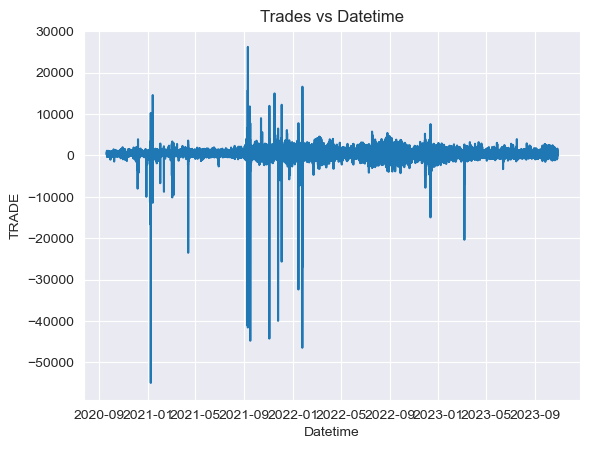

In [22]:
import matplotlib.pyplot as plt

plt.plot(energy_data["datetime"], energy_data["TRADE"])
plt.title("Trades vs Datetime")
plt.xlabel("Datetime")
plt.ylabel("TRADE")

plt.show()

In [23]:
import pandas as pd
import xarray as xr
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.iolib.smpickle import load_pickle

import comp_utils

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import pickle as pkl

dwd_Hornsea1 = xr.open_dataset("data/dwd_icon_eu_hornsea_1_20200920_20231027.nc")
dwd_Hornsea1_features = dwd_Hornsea1["WindSpeed:100"].mean(dim=["latitude","longitude"]).to_dataframe().reset_index()
dwd_Hornsea1_features["ref_datetime"] = dwd_Hornsea1_features["ref_datetime"].dt.tz_localize("UTC")
dwd_Hornsea1_features["valid_datetime"] = dwd_Hornsea1_features["ref_datetime"] + pd.TimedeltaIndex(dwd_Hornsea1_features["valid_datetime"],unit="hours")
dwd_solar = xr.open_dataset("data/dwd_icon_eu_pes10_20200920_20231027.nc")
dwd_solar_features = dwd_solar["SolarDownwardRadiation"].mean(dim="point").to_dataframe().reset_index()
dwd_solar_features["ref_datetime"] = dwd_solar_features["ref_datetime"].dt.tz_localize("UTC")
dwd_solar_features["valid_datetime"] = dwd_solar_features["ref_datetime"] + pd.TimedeltaIndex(dwd_solar_features["valid_datetime"],unit="hours")
energy_data = pd.read_csv("data/Energy_Data_20200920_20231027.csv")
energy_data["dtm"] = pd.to_datetime(energy_data["dtm"])
energy_data["Wind_MWh_credit"] = 0.5*energy_data["Wind_MW"] - energy_data["boa_MWh"]
energy_data["Solar_MWh_credit"] = 0.5*energy_data["Solar_MW"]

modelling_table = dwd_Hornsea1_features.merge(dwd_solar_features,how="outer",on=["ref_datetime","valid_datetime"])
modelling_table = modelling_table.set_index("valid_datetime").groupby("ref_datetime").resample("30T").interpolate("linear")
modelling_table = modelling_table.drop(columns="ref_datetime",axis=1).reset_index()
modelling_table = modelling_table.merge(energy_data,how="inner",left_on="valid_datetime",right_on="dtm")
modelling_table = modelling_table[modelling_table["valid_datetime"] - modelling_table["ref_datetime"] < np.timedelta64(50,"h")]
modelling_table.rename(columns={"WindSpeed:100":"WindSpeed"},inplace=True)
modelling_table = modelling_table[modelling_table["SolarDownwardRadiation"].notnull()]
modelling_table = modelling_table[modelling_table["WindSpeed"].notnull()]
modelling_table["total_generation_MWh"] = modelling_table["Wind_MWh_credit"] + modelling_table["Solar_MWh_credit"]
mod = smf.quantreg('total_generation_MWh ~ bs(SolarDownwardRadiation,df=5) + bs(WindSpeed,df=8)',
                   data=modelling_table)


import pickle

loaded_models = {}


for quantile in range(10, 100, 10):
    with open(f"models/model_q{quantile}.pickle", 'rb') as file:
        loaded_models[f"q{quantile}"] = pickle.load(file)


In [29]:
for quantile in range(10,100,10):
    modelling_table[f"q{quantile}"] = loaded_models[f"q{quantile}"].predict(modelling_table)
    modelling_table.loc[modelling_table[f"q{quantile}"] < 0, f"q{quantile}"] = 0
    
    
def revenue(bid,y,day_ahead_price,single_system_price):
    return bid*day_ahead_price + (y-bid)*(single_system_price - 0.07*(y-bid))

submission_date = "2023-02-18"
submission_date_forecast = modelling_table.loc[modelling_table["ref_datetime"]==pd.to_datetime(submission_date,utc=True)]
market_day = pd.DataFrame({"datetime":comp_utils.day_ahead_market_times(today_date=pd.to_datetime(submission_date))})
market_day = market_day.merge(submission_date_forecast,how="left",left_on="datetime",right_on="valid_datetime")

keys = [f"q{quantile}" for quantile in range(10, 100, 10)]
dict_revenue = {}
for key in keys:
    market_day["market_bid"] = market_day[key]
    dict_revenue[key]= revenue(bid=market_day["market_bid"],
        y=market_day["total_generation_MWh"],
        day_ahead_price=market_day["DA_Price"],
        single_system_price=market_day["SS_Price"]).sum()
    
print(dict_revenue)
#using same quantile for all 30 minutes periods, we can use different quantiles during the day, which depends on the total_generation, DA_Price and SS_Price
# based on those 3 variables, build a classifier, SVM, Random Forest, GBDT...


{'q10': 1998334.9644685462, 'q20': 2071649.0004524626, 'q30': 2116955.196160103, 'q40': 2152746.816967466, 'q50': 2183451.1296765124, 'q60': 2213319.280453221, 'q70': 2243326.5334983924, 'q80': 2274940.488128757, 'q90': 2310684.364532875}
